# 01 · Exploratory Data Analysis

**Goal:** understand the data before modelling. Three questions:

1. How rare is fraud? (class imbalance)
2. Do fraudulent transactions look different in **Amount** and **Time**?
3. Which of the anonymised features `V1`–`V28` separate fraud from normal?

**Dataset:** 284,807 card transactions made by European cardholders over two days in September 2013
(ULB Machine Learning Group, via OpenML). `V1`–`V28` are principal components produced by PCA:
the bank anonymised the original features (merchant, location, ...) for confidentiality.
Only `Time` (seconds since the first transaction) and `Amount` are in their original form.

In [1]:
import sys
sys.path.append("..")  # so we can import the fraudguard package from the project root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraudguard.config import FIGURES_DIR, PCA_FEATURES, TARGET
from fraudguard.data import load_data
from fraudguard.plotting import FRAUD_COLOR, NORMAL_COLOR, apply_style

apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Load and sanity-check

In [2]:
df = load_data()
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Column types:", df.dtypes.value_counts().to_dict())
print("Duplicate rows:", df.duplicated().sum(), "of which fraud:", df[df.duplicated()][TARGET].sum())

Missing values: 0
Column types: {dtype('float64'): 30, dtype('int64'): 1}


Duplicate rows: 1081 of which fraud: 19


No missing values and every column is numeric, so there is no cleaning to do. About 1,000 rows are exact
duplicates. We **keep** them: in real card data the same purchase can legitimately appear twice
(for example two identical coffees), and the dataset authors did not flag them as errors.

## 1 · Class imbalance

Normal: 284,315   Fraud: 492   Fraud rate: 0.173%


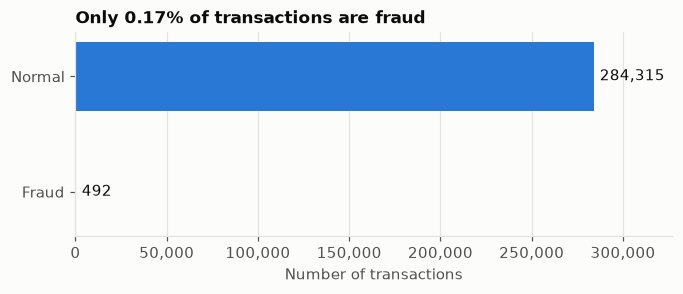

In [4]:
counts = df[TARGET].value_counts().sort_index()
fraud_pct = counts[1] / counts.sum() * 100
print(f"Normal: {counts[0]:,}   Fraud: {counts[1]:,}   Fraud rate: {fraud_pct:.3f}%")

fig, ax = plt.subplots(figsize=(7, 2.4))
bars = ax.barh(["Fraud", "Normal"], [counts[1], counts[0]], color=[FRAUD_COLOR, NORMAL_COLOR], height=0.6)
for bar, value in zip(bars, [counts[1], counts[0]]):
    ax.text(bar.get_width() + 3000, bar.get_y() + bar.get_height() / 2, f"{value:,}", va="center")
ax.set_title(f"Only {fraud_pct:.2f}% of transactions are fraud")
ax.set_xlabel("Number of transactions")
ax.set_xlim(0, counts[0] * 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "class_imbalance.png")
plt.show()

**Why this matters: the accuracy trap.** A "model" that ignores the input and always says *not fraud*:

In [5]:
always_normal_accuracy = (df[TARGET] == 0).mean()
print(f"Accuracy of predicting 'never fraud': {always_normal_accuracy:.4%}")
print(f"Frauds it catches: 0 of {counts[1]}")

Accuracy of predicting 'never fraud': 99.8273%
Frauds it catches: 0 of 492


**Observation:** 99.83% accuracy while catching *zero* frauds. Accuracy is dominated by the majority class,
so it is useless here. We will judge models with **precision, recall, F1 and PR-AUC**, which focus on
the fraud class.

## 2 · Amount

In [6]:
df.groupby(TARGET)["Amount"].describe().rename(index={0: "Normal", 1: "Fraud"}).round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normal,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


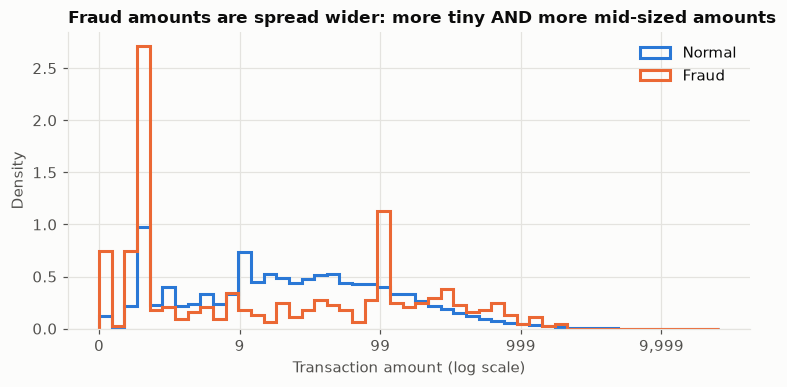

Share of zero-amount transactions: normal 0.6%, fraud 5.5%


In [7]:
# Amounts are very skewed (most are small, a few are huge), so we plot log10(Amount + 1).
# density=True puts both classes on the same scale even though fraud is 578x rarer.
bins = np.linspace(0, np.log10(df["Amount"].max() + 1), 50)
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, color, name in [(0, NORMAL_COLOR, "Normal"), (1, FRAUD_COLOR, "Fraud")]:
    ax.hist(np.log10(df.loc[df[TARGET] == label, "Amount"] + 1), bins=bins, density=True,
            histtype="step", linewidth=2, color=color, label=name)
ax.set_xticks([0, 1, 2, 3, 4], ["0", "9", "99", "999", "9,999"])
ax.set_xlabel("Transaction amount (log scale)")
ax.set_ylabel("Density")
ax.set_title("Fraud amounts are spread wider: more tiny AND more mid-sized amounts")
ax.legend()
fig.savefig(FIGURES_DIR / "amount_distribution.png")
plt.show()

zero = df.groupby(TARGET)["Amount"].apply(lambda s: (s == 0).mean())
print(f"Share of zero-amount transactions: normal {zero[0]:.1%}, fraud {zero[1]:.1%}")

**Observations:**
- The dataset does not state the currency (likely EUR), so amounts are shown as plain numbers.
- The **median fraud is only 9.25** (normal: 22). Fraudsters often make small "test" charges to check that
  a stolen card works before spending more. 5.5% of frauds have amount 0 (normal: 0.6%), which fits that card-testing pattern.
- But the **mean fraud is higher** (122 vs 88) and no fraud exceeds 2,126, so fraud amounts are spread
  differently, not simply larger.
- Amount alone cannot separate the classes (the curves overlap heavily), but it is a useful signal. It also
  matters for the **cost model** later: missing a 2,000 fraud is worse than missing a 1.00 one.

## 3 · Time
`Time` is seconds since the first transaction in the file and covers 48 hours. We don't know the real
clock time of "second 0", but the volume pattern below strongly suggests it is around midnight.

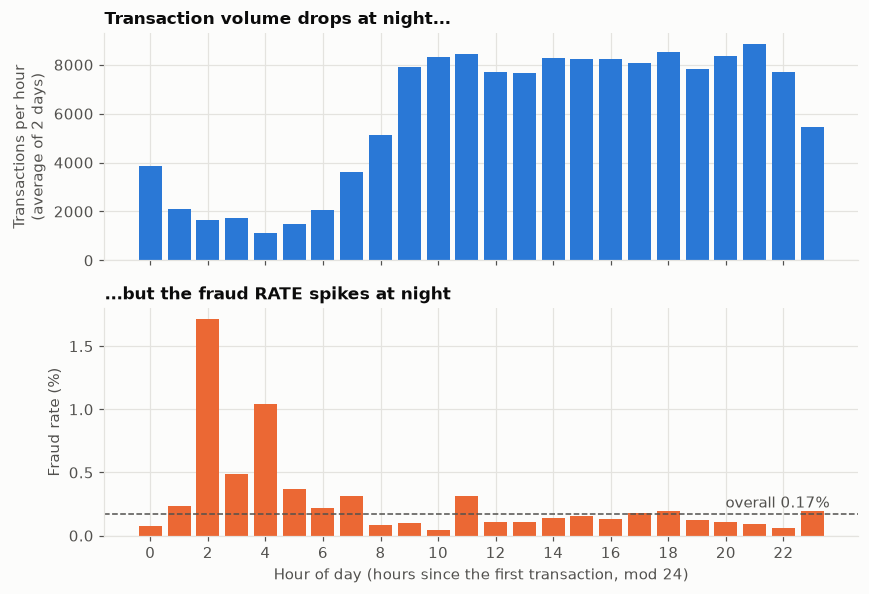

,transactions,frauds,fraud_rate_pct
Time,,,
2.0,3328,57,1.712740
4.0,2209,23,1.041195
3.0,3492,17,0.486827
5.0,2990,11,0.367893


In [8]:
hours = (df["Time"] // 3600) % 24  # hour of day, assuming the data starts at midnight
by_hour = df.groupby(hours)[TARGET].agg(transactions="count", frauds="sum")
by_hour["fraud_rate_pct"] = by_hour["frauds"] / by_hour["transactions"] * 100

# Two separate charts rather than one chart with two y-axes (easier to read honestly).
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
ax1.bar(by_hour.index, by_hour["transactions"] / 2, color=NORMAL_COLOR, width=0.8)
ax1.set_ylabel("Transactions per hour\n(average of 2 days)")
ax1.set_title("Transaction volume drops at night...")
ax2.bar(by_hour.index, by_hour["fraud_rate_pct"], color=FRAUD_COLOR, width=0.8)
ax2.axhline(fraud_pct, color="#52514e", linestyle="--", linewidth=1)
ax2.text(23.6, fraud_pct + 0.05, f"overall {fraud_pct:.2f}%", ha="right", color="#52514e")
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xlabel("Hour of day (hours since the first transaction, mod 24)")
ax2.set_title("...but the fraud RATE spikes at night")
ax2.set_xticks(range(0, 24, 2))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "time_patterns.png")
plt.show()

by_hour.sort_values("fraud_rate_pct", ascending=False).head(4)

**Observations:**
- Normal activity follows a clear day/night cycle: volume drops sharply between roughly hours 1 and 7.
- Fraud does **not** follow that cycle as strongly, so the fraud *rate* jumps at night: hour 2 has a 1.7% fraud
  rate, about **10× the average**. Fraudsters (often automated) don't sleep.
- Caveat: hour 0 is "the first transaction in the file", not a confirmed midnight, and two days is a very short
  window. We keep `Time` as a feature but should not over-trust it.

## 4 · The anonymised features V1–V28
We can't interpret them by name, but we can see which ones differ most between fraud and normal.

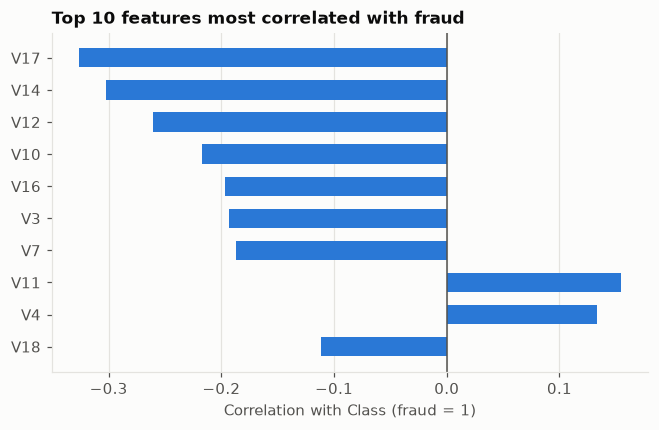

In [9]:
corr = df[PCA_FEATURES + ["Amount", "Time"]].corrwith(df[TARGET]).sort_values(key=abs, ascending=False)
top = corr.head(10)[::-1]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=NORMAL_COLOR, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Correlation with Class (fraud = 1)")
ax.set_title("Top 10 features most correlated with fraud")
ax.grid(axis="y", visible=False)
plt.show()

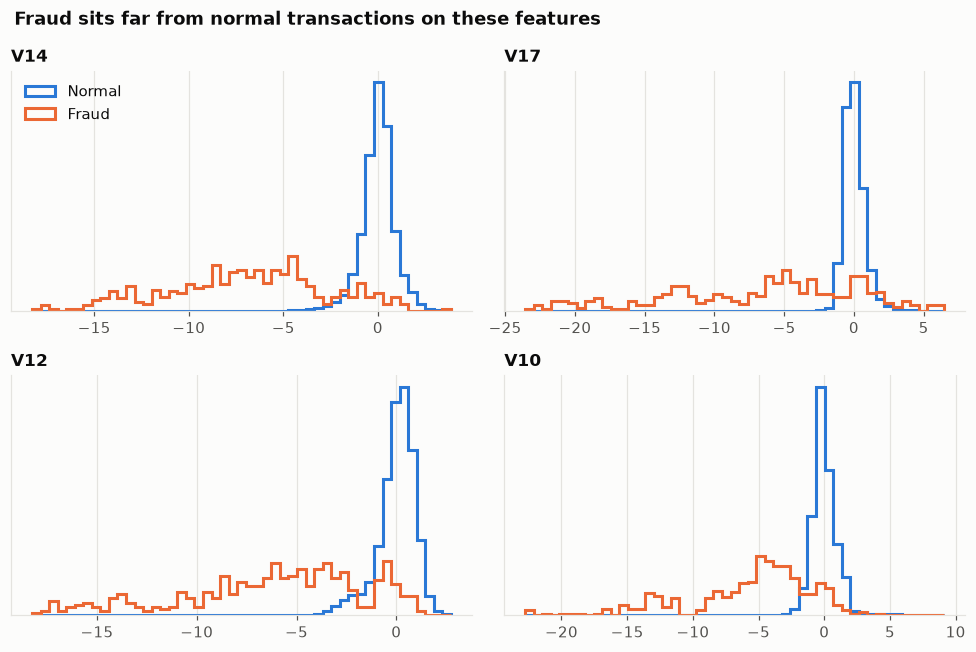

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, feature in zip(axes.flat, ["V14", "V17", "V12", "V10"]):
    # Range covers 99% of frauds and 99.8% of normal transactions (ignores extreme outliers).
    is_fraud = df[TARGET] == 1
    low = min(df[feature].quantile(0.001), df.loc[is_fraud, feature].quantile(0.005))
    high = max(df[feature].quantile(0.999), df.loc[is_fraud, feature].quantile(0.995))
    bins = np.linspace(low, high, 50)
    for label, color, name in [(0, NORMAL_COLOR, "Normal"), (1, FRAUD_COLOR, "Fraud")]:
        ax.hist(df.loc[df[TARGET] == label, feature], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=name)
    ax.set_title(feature)
    ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Fraud sits far from normal transactions on these features", fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "top_features.png")
plt.show()

**Observations:**
- `V17`, `V14`, `V12` and `V10` have the strongest (negative) correlation with fraud. Fraud transactions
  take much **lower** values on them, and the two distributions barely overlap. These will likely be the most
  important features for the models.
- `Amount` and `Time` have almost no *linear* correlation with fraud. Section 3 showed that the time pattern is
  non-linear (night vs day), which tree models such as Random Forest and XGBoost can capture but a linear
  model cannot.
- Honest limitation: since the V features are PCA components, we can say *"low V14 indicates fraud"* but not
  *what V14 means* in business terms.

## Summary and implications for modelling

| Finding | What we do about it |
|---|---|
| Fraud is 0.17% of the data | Stratified split; class weights or SMOTE; never judge by accuracy |
| Accuracy of "never fraud" is 99.83% | Use precision, recall, F1, PR-AUC |
| Amount and Time are on very different scales from V1–V28 | Scale `Amount` and `Time` (the V's are already PCA-scaled) |
| Missed frauds cost money in proportion to Amount | Choose the decision threshold with a cost model |
| A few V features separate the classes strongly | Expect good results; explain with SHAP |
| Time has a non-linear night pattern | Tree models (RF, XGBoost) should help |